# Artificial Scattering for Ray Effect Mitigation

Discrete ordinates (S$_N$) only transports particles along a finite set of
directions. Around a localized source in a weakly scattering medium, the flux
streams out along those directions and leaves unphysical streaks between them.
These are called *ray effects*.

ANTS can reduce ray effects with artificial scattering (as-S$_N$), following
Frank, Kusch, Camminady & Hauck (2020), "Ray Effect Mitigation for the Discrete
Ordinates Method Using Artificial Scattering", *Nuclear Science and
Engineering*. A forward-peaked scattering term is added to the transport
equation:

$$
\Omega_q \cdot \nabla \psi_q + (\sigma_t + \sigma_{as})\, \psi_q
    = \sigma_s \phi + \sum_p M_{as}[q, p]\, \psi_p + q_\text{ext}
$$

Each row of $M_{as}$ sums to $\sigma_{as}$, so the added out-scattering and
in-scattering balance and particles are conserved. The kernel only couples
nearby ordinates, which smears flux into the gaps between directions.

Artificial scattering is enabled through two `SolverData` fields:

* `sigma_as`: the artificial scattering strength (default `0.0`, disabled)
* `beta_as`: the kernel width (default `4.5`; larger is wider)

This example solves the same problem three ways:

1. standard S$_N$ with a coarse quadrature,
2. as-S$_N$ with the same coarse quadrature, and
3. a fine quadrature as the reference.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LogNorm
from scipy.interpolate import RegularGridInterpolator

import ants
from ants.datatypes import (
    GeometryData,
    MaterialData,
    SolverData,
    SourceData,
    SpatialDiscretization,
)
from ants.fixed2d import fixed_source

## Problem setup

A 6 cm x 6 cm pure absorber ($\sigma_t = 1$ cm$^{-1}$, no scattering) with a
small isotropic source at the center and vacuum boundaries. With no physical
scattering to redistribute particles, this is a worst case for ray effects.

Step differencing is used because it keeps the flux positive near the
localized source, which is needed for the log-scale plots below.

In [2]:
cells = 100
length = 6.0
delta = np.repeat(length / cells, cells)
centers = (np.arange(cells) + 0.5) * delta[0]

mat_data = MaterialData(
    total=np.array([[1.0]]),
    scatter=np.array([[[0.0]]]),
    fission=np.array([[[0.0]]]),
)

# Isotropic source in the central 4 x 4 cells (0.24 cm x 0.24 cm)
external = np.zeros((cells, cells, 1, 1))
middle = slice(cells // 2 - 2, cells // 2 + 2)
external[middle, middle] = 1.0

sources = SourceData(
    external=external,
    boundary_x=np.zeros((2, 1, 1, 1)),
    boundary_y=np.zeros((2, 1, 1, 1)),
)

geometry = GeometryData(
    medium_map=np.zeros((cells, cells), dtype=np.int32),
    delta_x=delta,
    delta_y=delta,
    bc_x=[0, 0],
    bc_y=[0, 0],
    geometry=3,  # 2D slab
    space_disc=SpatialDiscretization.STEP,
)


def solve(angles, sigma_as=0.0, beta_as=4.5):
    """Return the scalar flux for a quadrature with angles per dimension."""
    quadrature = ants.angular_xy(angles)
    # The lagged artificial scattering source needs more than the default
    # 100 iterations for the larger values of sigma_as below
    solver = SolverData(sigma_as=sigma_as, beta_as=beta_as, max_iter_angular=1000)
    flux = fixed_source(mat_data, sources, geometry, quadrature, solver)
    return flux[..., 0]

## Solving with and without artificial scattering

`angular_xy(4)` gives 16 directions, which is coarse enough to show strong ray
effects. The reference uses `angular_xy(32)` (1024 directions). At that
resolution the flux changes by less than 0.2% from `angular_xy(24)`.

In [3]:
coarse = 4
sigma_as = 7.5

flux_ref = solve(32)
flux_sn = solve(coarse)
flux_as = solve(coarse, sigma_as=sigma_as)


def rel_error(flux):
    return np.linalg.norm(flux - flux_ref) / np.linalg.norm(flux_ref)


print(f"Standard SN relative L2 error: {rel_error(flux_sn):.3f}")
print(f"as-SN       relative L2 error: {rel_error(flux_as):.3f}")

Standard SN relative L2 error: 0.117
as-SN       relative L2 error: 0.082


The flux falls off by several orders of magnitude from the source, so it
is plotted on a log scale. All three panels share one color scale.

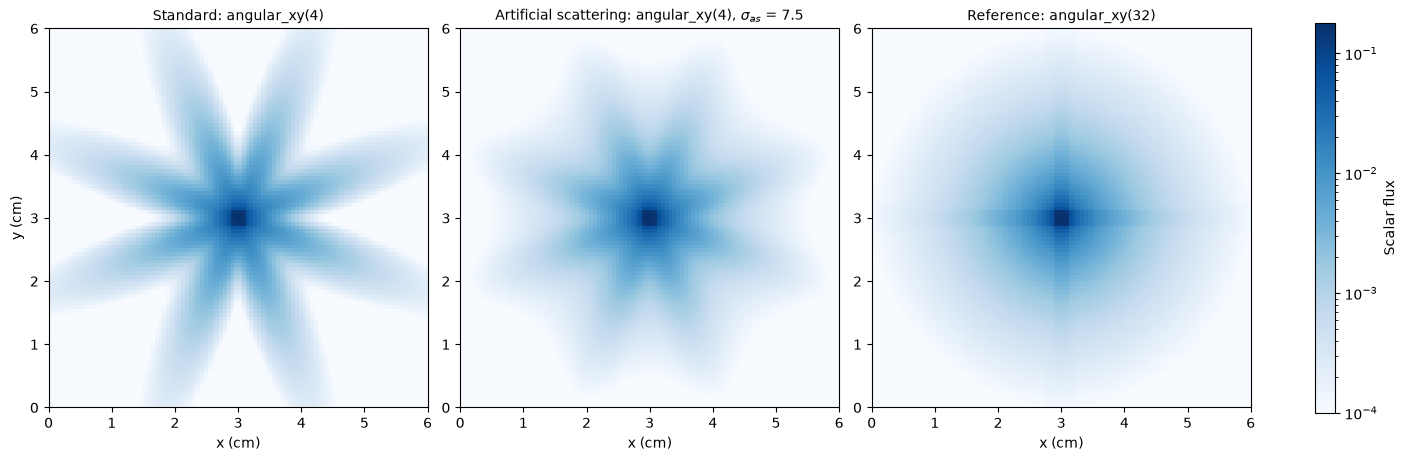

In [4]:
panels = [
    (flux_sn, f"Standard: angular_xy({coarse})"),
    (flux_as, f"Artificial scattering: angular_xy({coarse}), $\\sigma_{{as}}$ = {sigma_as:g}"),
    (flux_ref, "Reference: angular_xy(32)"),
]
norm = LogNorm(vmin=1e-4, vmax=flux_ref.max())

fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), constrained_layout=True)
for ax, (flux, title) in zip(axes, panels):
    mesh = ax.pcolormesh(
        centers, centers, flux.T, norm=norm, cmap="Blues", shading="auto"
    )
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("x (cm)")
    ax.set_aspect("equal")
axes[0].set_ylabel("y (cm)")
fig.colorbar(mesh, ax=axes, label="Scalar flux", shrink=0.9)
plt.show()

With 16 directions the standard solution is a set of distinct beams with
almost no flux between them. Artificial scattering spreads flux into those
gaps. The beams are still visible at this strength, but the flux between
them is much closer to the reference.

A sharper test is the flux around a circle centered on the source. Without ray
effects it should be close to the reference profile at every angle. The
reference profile is not perfectly flat because the source is a square on a
Cartesian grid.

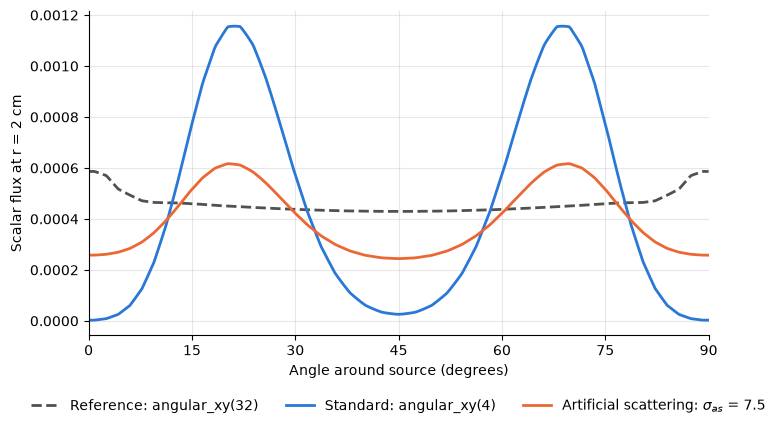

Mean flux on the circle / reference: standard 0.99, as-SN 0.86
Total flux / reference:              as-SN 1.010


In [5]:
radius = 2.0
theta = np.linspace(0.0, 0.5 * np.pi, 361)  # one quadrant, by symmetry


def on_circle(flux):
    points = np.column_stack(
        [0.5 * length + radius * np.cos(theta), 0.5 * length + radius * np.sin(theta)]
    )
    return RegularGridInterpolator((centers, centers), flux)(points)


fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(np.degrees(theta), on_circle(flux_ref), color="#52514e", lw=2,
        ls="--", label="Reference: angular_xy(32)")
ax.plot(np.degrees(theta), on_circle(flux_sn), color="#2a78d6", lw=2,
        label=f"Standard: angular_xy({coarse})")
ax.plot(np.degrees(theta), on_circle(flux_as), color="#eb6834", lw=2,
        label=f"Artificial scattering: $\\sigma_{{as}}$ = {sigma_as:g}")
ax.set_xlabel("Angle around source (degrees)")
ax.set_ylabel(f"Scalar flux at r = {radius:g} cm")
ax.set_xlim(0, 90)
ax.set_xticks(np.arange(0, 91, 15))
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3)
plt.show()

ratio_sn = on_circle(flux_sn).mean() / on_circle(flux_ref).mean()
ratio_as = on_circle(flux_as).mean() / on_circle(flux_ref).mean()
total_as = flux_as.sum() / flux_ref.sum()
print(f"Mean flux on the circle / reference: standard {ratio_sn:.2f}, as-SN {ratio_as:.2f}")
print(f"Total flux / reference:              as-SN {total_as:.3f}")

Artificial scattering reduces the oscillation, but it also lowers the flux
on the circle relative to the reference. This is a bias of the method in an
absorber. Each artificial scattering event redirects a particle slightly, so
the particle travels a longer path to reach the circle, and more particles
are absorbed on the way. The total flux, which is proportional to total track
length, is slightly higher than the reference for the same reason.

## Choosing $\sigma_{as}$

Artificial scattering trades ray effects for added smoothing. Too little
leaves the beams in place. Too much over-smooths the solution and acts like
a real scattering medium. The sweep below tracks two measures:

* the coefficient of variation (CoV) of the flux on the circle above, which
  measures how strong the ray effects are, and
* the relative L2 error against the reference over the whole domain.

The sweep is run for the default kernel width, `beta_as = 4.5`, and for a
kernel twice as wide, `beta_as = 9`. Larger `sigma_as` also needs more source
iterations, because the artificial in-scattering term is lagged between
iterations. This is why `solve` raises `max_iter_angular`, and ANTS warns if
the iterations stop at the limit before converging.

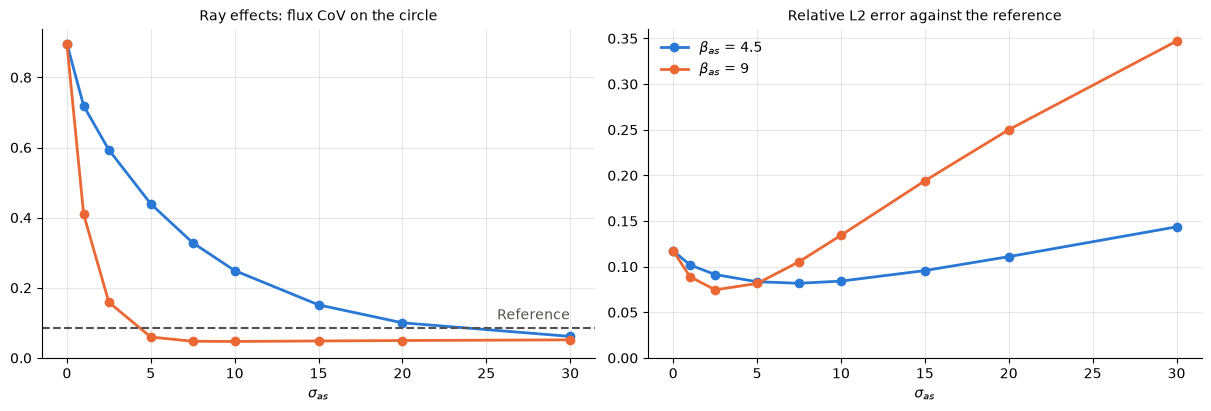

beta_as = 4.5
  sigma_as =   0.0   CoV = 0.896   L2 error = 0.117
  sigma_as =   1.0   CoV = 0.719   L2 error = 0.102
  sigma_as =   2.5   CoV = 0.593   L2 error = 0.091
  sigma_as =   5.0   CoV = 0.439   L2 error = 0.083
  sigma_as =   7.5   CoV = 0.328   L2 error = 0.082
  sigma_as =  10.0   CoV = 0.249   L2 error = 0.084
  sigma_as =  15.0   CoV = 0.151   L2 error = 0.096
  sigma_as =  20.0   CoV = 0.100   L2 error = 0.111
  sigma_as =  30.0   CoV = 0.061   L2 error = 0.144
beta_as = 9
  sigma_as =   0.0   CoV = 0.896   L2 error = 0.117
  sigma_as =   1.0   CoV = 0.409   L2 error = 0.089
  sigma_as =   2.5   CoV = 0.159   L2 error = 0.075
  sigma_as =   5.0   CoV = 0.060   L2 error = 0.082
  sigma_as =   7.5   CoV = 0.048   L2 error = 0.105
  sigma_as =  10.0   CoV = 0.047   L2 error = 0.134
  sigma_as =  15.0   CoV = 0.048   L2 error = 0.194
  sigma_as =  20.0   CoV = 0.050   L2 error = 0.250
  sigma_as =  30.0   CoV = 0.052   L2 error = 0.347


In [6]:
sweep = np.array([0.0, 1.0, 2.5, 5.0, 7.5, 10.0, 15.0, 20.0, 30.0])
widths = {4.5: "#2a78d6", 9.0: "#eb6834"}
cov, error = {}, {}
for beta_as in widths:
    cov[beta_as], error[beta_as] = [], []
    for value in sweep:
        flux = solve(coarse, sigma_as=value, beta_as=beta_as)
        ring = on_circle(flux)
        cov[beta_as].append(ring.std() / ring.mean())
        error[beta_as].append(rel_error(flux))

ring_ref = on_circle(flux_ref)
cov_ref = ring_ref.std() / ring_ref.mean()

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for beta_as, color in widths.items():
    label = f"$\\beta_{{as}}$ = {beta_as:g}"
    ax0.plot(sweep, cov[beta_as], color=color, lw=2, marker="o", ms=6, label=label)
    ax1.plot(sweep, error[beta_as], color=color, lw=2, marker="o", ms=6, label=label)
ax0.axhline(cov_ref, color="#52514e", lw=1.5, ls="--")
ax0.annotate("Reference", (sweep[-1], cov_ref), xytext=(0, 6),
             textcoords="offset points", ha="right", color="#52514e")
ax0.set_title("Ray effects: flux CoV on the circle", fontsize=10)
ax0.set_ylim(bottom=0)

ax1.set_title("Relative L2 error against the reference", fontsize=10)
ax1.set_ylim(bottom=0)
ax1.legend(frameon=False)

for ax in (ax0, ax1):
    ax.set_xlabel("$\\sigma_{as}$")
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
plt.show()

for beta_as in widths:
    print(f"beta_as = {beta_as:g}")
    for value, c, e in zip(sweep, cov[beta_as], error[beta_as]):
        print(f"  sigma_as = {value:5.1f}   CoV = {c:.3f}   L2 error = {e:.3f}")

With the default kernel width, the overall error is lowest around
$\sigma_{as} \approx 5$-$10$ for this problem, but the ray effects fall
slowly. The CoV only reaches the reference value near $\sigma_{as} \approx 25$,
where the flux on the circle is far too low. The wider kernel moves flux
further with each artificial scattering event, so it removes the ray effects
with less $\sigma_{as}$ and less bias, and it gives the lowest error, around
$\sigma_{as} \approx 2.5$. Past the best value the extra smoothing costs more
accuracy than it recovers. Once the CoV drops below the reference value, the
solution is smoother than the true flux, which is a clear sign of too much
artificial scattering. The best values depend on the problem, the quadrature
and the mesh, so it is worth running a short sweep like this one for new
problems.

## Notes

* Artificial scattering is available in the 2D solvers: `fixed2d`, `timed2d`
  (all time discretizations) and `hybrid2d`, and in the 3D `fixed3d`. It has
  no effect when `sigma_as = 0`. It is not used by `critical2d` or `vhybrid2d`.
* `beta_as` sets the kernel width $\epsilon = \beta / N_q$, where $N_q$ is the
  number of directions on the full sphere, as in Frank et al. (2020).
  `angular_xy(N)` keeps the $N^2$ directions in the upper hemisphere, so
  $N_q = 2 N^2$. Each 2D direction also receives the artificial scattering of
  its reflection through the x-y plane, so a 2D problem has the same artificial
  scattering as a 3D problem that does not change in z. Frank et al. use about
  4.5 for explicit and 4.0 for implicit schemes, but a coarse quadrature like
  the one here can do better with a wider kernel.
* Artificial scattering does not replace angular refinement. It makes a
  coarse quadrature more usable, but the converged answer still comes from a
  finer quadrature.